# ch07_1. CNN → YOLO 연결 1단계 — Single Object Localization

## 개요

기존 CNN(Classification, 분류)은 **이미지가 무엇인지** 예측한다.

이번 단계에서는 CNN에 Bounding Box(바운딩 박스, 객체 위치) 예측을 추가하여 다음 두 가지를 동시에 학습한다.

```text
① What?  → Class
② Where? → Bounding Box
```

전체 학습 흐름:

```text
CNN Classification
        ↓
Single Object Localization
        ↓
Object Detection
        ↓
YOLO
```

이번 노트북은 학습 흐름이 숨겨지지 않도록 **데이터 준비 → 모델 → Loss → 학습 → 검증 → 예측**을 위에서 아래로 직접 실행한다.


In [38]:
# 01. 라이브러리 불러오기

import random

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset

from torchvision import datasets, transforms

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


### 코드 풀이 — 이 코드가 무엇을 하는가

- `Dataset` : 이미지, Class 정답, Bounding Box 정답을 한 샘플로 제공한다.
- `DataLoader` : 여러 샘플을 Batch 단위로 묶는다.
- `Subset` : 처음 실습에서는 전체 MNIST 중 일부만 사용한다.
- `Rectangle` : 정답 Box와 예측 Box를 이미지 위에 표시한다.

기존 CNN 실습에 **Bounding Box 데이터 처리와 시각화 기능**이 추가되었다.


In [39]:
# 02. Random Seed와 Device 설정

torch.manual_seed(42)
random.seed(42)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("device:", device)


device: cuda


### 실행 결과 예시

```text
device: cuda
```

GPU를 사용할 수 없으면 `cpu`가 출력된다.

### 코드 풀이

Random Seed를 고정하면 실습할 때 초기 조건이 지나치게 달라지는 것을 줄일 수 있다.


In [40]:
# 03. MNIST 데이터 불러오기

mnist_train = datasets.MNIST(
    root="./data",
    train=True,
    download=True
)

mnist_test = datasets.MNIST(
    root="./data",
    train=False,
    download=True
)

print("Train 데이터 수:", len(mnist_train))
print("Test 데이터 수 :", len(mnist_test))


Train 데이터 수: 60000
Test 데이터 수 : 10000


### 실행 결과

```text
Train 데이터 수: 60000
Test 데이터 수 : 10000
```

### 코드 풀이

기존 MNIST 한 샘플은 다음 두 값으로 구성된다.

```text
Image → 28 × 28 흑백 이미지
Label → 숫자 0 ~ 9
```

이번 단계에서는 여기에 **Bounding Box 정답**을 추가한다.


In [41]:
# 04. Single Object Localization용 Dataset 정의

class LocalizedMNIST(Dataset):

    def __init__(
        self,
        base_dataset,
        canvas_size=64,
        random_position=True
    ):
        self.base_dataset = base_dataset
        self.canvas_size = canvas_size
        self.random_position = random_position
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):

        image, label = self.base_dataset[idx]

        # PIL Image → Tensor
        digit = self.to_tensor(image)

        # 실제 숫자가 존재하는 픽셀 영역 찾기
        mask = digit[0] > 0.05
        ys, xs = torch.where(mask)

        y1 = ys.min().item()
        y2 = ys.max().item() + 1
        x1 = xs.min().item()
        x2 = xs.max().item() + 1

        # 숫자 주변의 빈 공간 제거
        digit = digit[:, y1:y2, x1:x2]

        h = digit.shape[1]
        w = digit.shape[2]

        max_x = self.canvas_size - w
        max_y = self.canvas_size - h

        # Train: 숫자 위치를 계속 변경
        if self.random_position:
            x0 = random.randint(0, max_x)
            y0 = random.randint(0, max_y)

        # Validation: 같은 idx는 항상 같은 위치
        else:
            generator = torch.Generator()
            generator.manual_seed(idx + 1000)

            x0 = torch.randint(
                0, max_x + 1, (1,),
                generator=generator
            ).item()

            y0 = torch.randint(
                0, max_y + 1, (1,),
                generator=generator
            ).item()

        # 64 × 64 검은 배경
        canvas = torch.zeros(
            1,
            self.canvas_size,
            self.canvas_size
        )

        # 숫자를 임의 위치에 삽입
        canvas[:, y0:y0 + h, x0:x0 + w] = digit

        # Bounding Box 중심 좌표와 크기 정규화
        cx = (x0 + w / 2) / self.canvas_size
        cy = (y0 + h / 2) / self.canvas_size
        bw = w / self.canvas_size
        bh = h / self.canvas_size

        bbox = torch.tensor(
            [cx, cy, bw, bh],
            dtype=torch.float32
        )

        return canvas, label, bbox


### 코드 풀이 — Dataset에서 무엇이 달라졌는가

기존 CNN Dataset:

```text
Image + Label
```

이번 Localization Dataset:

```text
Image + Label + Bounding Box
```

핵심은 마지막 반환값이다.

```python
return canvas, label, bbox
```

`bbox`는 다음 순서로 저장한다.

```text
[cx, cy, w, h]

cx → 객체 중심의 x 위치
cy → 객체 중심의 y 위치
w  → 객체의 폭
h  → 객체의 높이
```

모든 값은 `0 ~ 1` 범위로 정규화한다. 이 형식은 이후 YOLO의 Bounding Box 개념과 직접 연결된다.


In [42]:
# 05. 학습용 / 검증용 데이터 일부 선택

generator = torch.Generator().manual_seed(42)

train_indices = torch.randperm(
    len(mnist_train),
    generator=generator
)[:20000]

val_indices = torch.arange(5000)

train_base = Subset(
    mnist_train,
    train_indices
)

val_base = Subset(
    mnist_test,
    val_indices
)

print("Train 사용 데이터:", len(train_base))
print("Validation 사용 데이터:", len(val_base))


Train 사용 데이터: 20000
Validation 사용 데이터: 5000


### 실행 결과

```text
Train 사용 데이터: 20000
Validation 사용 데이터: 5000
```

### 코드 풀이

처음 단계에서는 구조 이해가 목적이므로 학습 시간을 줄이기 위해 일부 데이터만 사용한다.


In [43]:
# 06. Localization Dataset과 DataLoader 생성

train_dataset = LocalizedMNIST(
    train_base,
    canvas_size=64,
    random_position=True
)

val_dataset = LocalizedMNIST(
    val_base,
    canvas_size=64,
    random_position=False
)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


### 코드 풀이 — Train과 Validation의 차이

Train에서는 숫자의 위치가 계속 바뀔 수 있다.

```text
같은 숫자 7
Epoch 1 → 왼쪽
Epoch 2 → 오른쪽
Epoch 3 → 아래쪽
```

따라서 모델이 위치를 외우지 않고 **실제로 위치 특징을 학습**하게 된다.

Validation에서는 같은 데이터가 항상 같은 위치에 나오도록 하여 성능 비교 조건을 일정하게 만든다.


In [44]:
# 07. 실제 Tensor Shape 확인

images, labels, boxes = next(
    iter(train_loader)
)

print("images :", images.shape)
print("labels :", labels.shape)
print("boxes  :", boxes.shape)


images : torch.Size([64, 1, 64, 64])
labels : torch.Size([64])
boxes  : torch.Size([64, 4])


### 실행 결과

```text
images : torch.Size([64, 1, 64, 64])
labels : torch.Size([64])
boxes  : torch.Size([64, 4])
```

### 코드 풀이

```text
images → 64장의 64 × 64 흑백 이미지
labels → 64개의 Class 정답
boxes  → 64개의 Bounding Box 정답
```

`boxes.shape = [64, 4]`에서 `4`는 다음 네 좌표를 의미한다.

```text
[cx, cy, w, h]
```


In [45]:
# 08. Bounding Box 표시 함수

def draw_box(
    ax,
    box,
    canvas_size,
    label,
    edgecolor,
    linestyle="-"
):

    cx, cy, w, h = box.tolist()

    # 0 ~ 1 정규화 좌표 → Pixel 좌표
    cx *= canvas_size
    cy *= canvas_size
    w *= canvas_size
    h *= canvas_size

    # 중심 좌표 → 왼쪽 위 좌표
    x1 = cx - w / 2
    y1 = cy - h / 2

    rectangle = Rectangle(
        (x1, y1),
        w,
        h,
        fill=False,
        edgecolor=edgecolor,
        linewidth=2,
        linestyle=linestyle
    )

    ax.add_patch(rectangle)

    ax.text(
        x1,
        max(y1 - 1.5, 1),
        label,
        color=edgecolor,
        fontsize=9,
        bbox={
            "facecolor": "black",
            "alpha": 0.5,
            "pad": 1
        }
    )


### 코드 풀이

이 함수는 학습 원리를 숨기는 함수가 아니라 **시각화 반복 코드를 줄이는 보조 함수**이다.

정규화된 Bounding Box를 실제 Pixel 좌표로 바꾼 뒤 이미지 위에 사각형을 그린다.


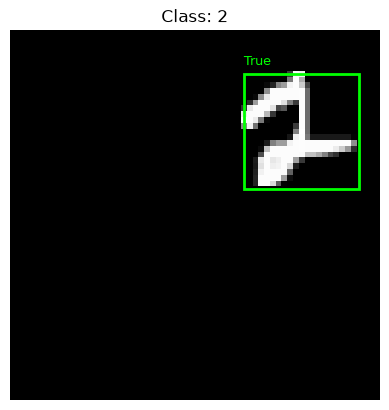

In [46]:
# 09. 학습 전 입력 이미지와 True Bounding Box 확인

sample_image = images[0]
sample_label = labels[0]
sample_box = boxes[0]

fig, ax = plt.subplots()

ax.imshow(
    sample_image.squeeze(),
    cmap="gray"
)

draw_box(
    ax,
    sample_box,
    64,
    "True",
    edgecolor="lime",
    linestyle="-"
)

ax.set_title(
    f"Class: {sample_label.item()}"
)

ax.axis("off")
plt.show()


### 코드 풀이 — 학습 전에 반드시 확인

Object Detection 계열에서는 학습 전에 먼저 **이미지와 정답 Box가 정확히 맞는지** 확인해야 한다.

```text
숫자 위치 정상?
+
True Box가 숫자를 정확히 감싸는가?
```

정답 데이터가 잘못되면 모델이 정상이어도 좋은 결과가 나올 수 없다.


In [47]:
# 10. CNN + Class Head + Box Head 모델 정의

class LocalizationCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # CNN Feature Extraction
        self.features = nn.Sequential(

            nn.Conv2d(
                1, 16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            ),

            nn.Conv2d(
                16, 32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            ),

            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(
                kernel_size=2,
                stride=2
            )
        )

        # 공통 Feature
        self.shared = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU()
        )

        # 무엇인가? → 숫자 0 ~ 9
        self.class_head = nn.Linear(
            128,
            10
        )

        # 어디에 있는가? → cx, cy, w, h
        self.box_head = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 4),
            nn.Sigmoid()
        )

    def forward(self, x):

        x = self.features(x)
        feature = self.shared(x)

        class_logits = self.class_head(
            feature
        )

        pred_boxes = self.box_head(
            feature
        )

        return class_logits, pred_boxes


### 코드 풀이 — 기존 CNN에서 무엇이 추가되었는가

기존 CNN:

```text
Image
 ↓
CNN
 ↓
Class
```

이번 모델:

```text
                CNN
                 ↓
          Shared Feature
                 │
        ┌────────┴────────┐
        ↓                 ↓
   Class Head          Box Head
        ↓                 ↓
     숫자 0~9        cx, cy, w, h
```

핵심은 **CNN으로 추출한 공통 Feature를 두 개의 출력 Head가 함께 사용한다는 것**이다.

- `class_head` → 무엇인가?
- `box_head` → 어디에 있는가?

`box_head` 마지막의 `Sigmoid()`는 예측 좌표를 `0 ~ 1` 범위로 제한한다.


## 11. CNN Feature Map 크기 변화

```text
입력       → [N, 1, 64, 64]
Conv/Pool  → [N, 16, 32, 32]
Conv/Pool  → [N, 32, 16, 16]
Conv/Pool  → [N, 64, 8, 8]
```

마지막 Feature Map을 Flatten하면:

```text
64 × 8 × 8
→ 4096개 Feature
```

가 되고, 이를 `128`개의 공통 Feature로 줄인 뒤 Class Head와 Box Head로 전달한다.


In [48]:
# 12. 모델 출력 Shape 확인

model = LocalizationCNN()

class_logits, pred_boxes = model(
    images
)

print(
    "class_logits:",
    class_logits.shape
)

print(
    "pred_boxes:",
    pred_boxes.shape
)


class_logits: torch.Size([64, 10])
pred_boxes: torch.Size([64, 4])


### 실행 결과

```text
class_logits: torch.Size([64, 10])
pred_boxes: torch.Size([64, 4])
```

### 코드 풀이 — CNN → Localization의 핵심 변화

기존 CNN 출력:

```text
[64, 10]
```

이번 출력:

```text
Class → [64, 10]
Box   → [64, 4]
```

즉 한 이미지마다 **Class Score 10개 + Bounding Box 좌표 4개**를 동시에 출력한다.


In [49]:
# 13. 모델, Loss Function, Optimizer 설정

model = LocalizationCNN().to(device)

# 무엇인가? → 다중분류
class_loss_function = nn.CrossEntropyLoss()

# 어디에 있는가? → 좌표 회귀
box_loss_function = nn.SmoothL1Loss()

BOX_WEIGHT = 5.0

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


### 코드 풀이 — 왜 Loss가 두 개인가

이번 모델은 두 문제를 동시에 푼다.

```text
Class
→ Classification
→ CrossEntropyLoss
```

```text
Bounding Box
→ Regression
→ SmoothL1Loss
```

학습할 때 두 Loss를 하나로 합친다.

```text
Total Loss
→ Class Loss + 5 × Box Loss
```

`BOX_WEIGHT = 5.0`은 위치 Loss의 영향도를 조절하기 위한 초기값이다.


In [50]:
# 14. Bounding Box 좌표 형식 변환
# [cx, cy, w, h] → [x1, y1, x2, y2]

def xywh_to_xyxy(boxes):

    cx = boxes[:, 0]
    cy = boxes[:, 1]
    w = boxes[:, 2]
    h = boxes[:, 3]

    x1 = cx - w / 2
    y1 = cy - h / 2
    x2 = cx + w / 2
    y2 = cy + h / 2

    return torch.stack(
        [x1, y1, x2, y2],
        dim=1
    )


### 코드 풀이

학습에서는 중심 좌표 형식인 `[cx, cy, w, h]`를 사용한다.

IoU 계산에서는 다음 형식이 편하다.

```text
[x1, y1, x2, y2]

x1, y1 → 왼쪽 위
x2, y2 → 오른쪽 아래
```


In [51]:
# 15. IoU 계산 함수

def calculate_iou(
    pred_boxes,
    target_boxes
):

    pred = xywh_to_xyxy(
        pred_boxes
    )

    target = xywh_to_xyxy(
        target_boxes
    )

    inter_x1 = torch.maximum(
        pred[:, 0], target[:, 0]
    )
    inter_y1 = torch.maximum(
        pred[:, 1], target[:, 1]
    )
    inter_x2 = torch.minimum(
        pred[:, 2], target[:, 2]
    )
    inter_y2 = torch.minimum(
        pred[:, 3], target[:, 3]
    )

    inter_w = (
        inter_x2 - inter_x1
    ).clamp(min=0)

    inter_h = (
        inter_y2 - inter_y1
    ).clamp(min=0)

    intersection = inter_w * inter_h

    pred_area = (
        (pred[:, 2] - pred[:, 0]).clamp(min=0)
        *
        (pred[:, 3] - pred[:, 1]).clamp(min=0)
    )

    target_area = (
        (target[:, 2] - target[:, 0]).clamp(min=0)
        *
        (target[:, 3] - target[:, 1]).clamp(min=0)
    )

    union = (
        pred_area
        + target_area
        - intersection
    )

    iou = intersection / (
        union + 1e-6
    )

    return iou


### 코드 풀이 — IoU

IoU(Intersection over Union, 두 박스의 겹침 비율)는 예측 Box가 정답 Box와 얼마나 잘 겹치는지 평가한다.

```text
          겹친 면적
IoU = ───────────────
       두 Box의 합집합
```

```text
IoU → 1 : 거의 정확하게 겹침
IoU → 0 : 거의 겹치지 않음
```

기존 CNN에서는 Accuracy를 주로 확인했지만, Localization에서는 **Accuracy + IoU**를 함께 본다.


In [52]:
# 16. 학습

EPOCHS = 5

for epoch in range(EPOCHS):

    model.train()

    train_loss_sum = 0.0
    train_class_loss_sum = 0.0
    train_box_loss_sum = 0.0

    train_correct = 0
    train_total = 0

    for images, labels, boxes in train_loader:

        images = images.to(device)
        labels = labels.to(device)
        boxes = boxes.to(device)

        # 이전 Gradient 초기화
        optimizer.zero_grad()

        # Forward
        class_logits, pred_boxes = model(
            images
        )

        # 무엇인가? → Class Loss
        class_loss = class_loss_function(
            class_logits,
            labels
        )

        # 어디인가? → Box Loss
        box_loss = box_loss_function(
            pred_boxes,
            boxes
        )

        # 두 Loss를 하나로 결합
        loss = (
            class_loss
            + BOX_WEIGHT * box_loss
        )

        # Backpropagation
        loss.backward()

        # Weight Update
        optimizer.step()

        batch_size = images.size(0)

        train_loss_sum += (
            loss.item() * batch_size
        )

        train_class_loss_sum += (
            class_loss.item() * batch_size
        )

        train_box_loss_sum += (
            box_loss.item() * batch_size
        )

        predictions = class_logits.argmax(
            dim=1
        )

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_class_loss = train_class_loss_sum / train_total
    train_box_loss = train_box_loss_sum / train_total
    train_accuracy = train_correct / train_total

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Total Loss: {train_loss:.4f} | "
        f"Class Loss: {train_class_loss:.4f} | "
        f"Box Loss: {train_box_loss:.4f} | "
        f"Accuracy: {train_accuracy:.4f}"
    )


Epoch 1/5 | Total Loss: 1.5703 | Class Loss: 1.5545 | Box Loss: 0.0032 | Accuracy: 0.4275
Epoch 2/5 | Total Loss: 0.5674 | Class Loss: 0.5633 | Box Loss: 0.0008 | Accuracy: 0.8213
Epoch 3/5 | Total Loss: 0.3547 | Class Loss: 0.3510 | Box Loss: 0.0007 | Accuracy: 0.8891
Epoch 4/5 | Total Loss: 0.2653 | Class Loss: 0.2622 | Box Loss: 0.0006 | Accuracy: 0.9177
Epoch 5/5 | Total Loss: 0.2160 | Class Loss: 0.2130 | Box Loss: 0.0006 | Accuracy: 0.9331


### 코드 풀이 — 이번 단계에서 가장 중요한 부분

핵심은 다음 네 줄이다.

```python
class_logits, pred_boxes = model(images)

class_loss = class_loss_function(
    class_logits,
    labels
)

box_loss = box_loss_function(
    pred_boxes,
    boxes
)

loss = class_loss + BOX_WEIGHT * box_loss
```

전체 흐름:

```text
               Image
                 ↓
                CNN
                 ↓
          Shared Feature
             │       │
             ↓       ↓
          Class     Box
             ↓       ↓
       Class Loss   Box Loss
             \       /
              \     /
              Total Loss
                  ↓
             backward()
                  ↓
          Weight Update
```

이 부분이 **CNN 분류 → Object Localization**으로 넘어가는 핵심 변화이다.


In [53]:
# 17. Validation

model.eval()

val_correct = 0
val_total = 0
iou_sum = 0.0

with torch.no_grad():

    for images, labels, boxes in val_loader:

        images = images.to(device)
        labels = labels.to(device)
        boxes = boxes.to(device)

        class_logits, pred_boxes = model(
            images
        )

        predictions = class_logits.argmax(
            dim=1
        )

        val_correct += (
            predictions == labels
        ).sum().item()

        val_total += labels.size(0)

        iou = calculate_iou(
            pred_boxes,
            boxes
        )

        iou_sum += iou.sum().item()

val_accuracy = val_correct / val_total
mean_iou = iou_sum / val_total

print(
    "Validation Accuracy:",
    f"{val_accuracy:.4f}"
)

print(
    "Mean IoU:",
    f"{mean_iou:.4f}"
)


Validation Accuracy: 0.9252
Mean IoU: 0.6470


### 코드 풀이 — Validation 결과 해석

이번에는 두 가지 결과를 함께 본다.

```text
Validation Accuracy
→ 숫자를 얼마나 잘 맞혔는가?
```

```text
Mean IoU
→ 위치를 얼마나 정확히 찾았는가?
```

분류 Accuracy가 높아도 IoU가 낮을 수 있으므로 **Class 성능과 위치 성능은 서로 다른 문제**이다.


In [54]:
# 18. 한 이미지 예측

model.eval()

images, labels, boxes = next(
    iter(val_loader)
)

sample_image = images[0]
true_label = labels[0]
true_box = boxes[0]

with torch.no_grad():

    class_logits, pred_boxes = model(
        sample_image
        .unsqueeze(0)
        .to(device)
    )

pred_class = class_logits.argmax(
    dim=1
).item()

pred_box = pred_boxes[0].cpu()

sample_iou = calculate_iou(
    pred_box.unsqueeze(0),
    true_box.unsqueeze(0)
).item()

print("정답 Class:", true_label.item())
print("예측 Class:", pred_class)
print("정답 Box:", true_box)
print("예측 Box:", pred_box)
print("IoU:", f"{sample_iou:.4f}")


정답 Class: 7
예측 Class: 7
정답 Box: tensor([0.8750, 0.3750, 0.2500, 0.3125])
예측 Box: tensor([0.8729, 0.4160, 0.2505, 0.3057])
IoU: 0.7546


### 실행 결과 해석

예를 들어:

```text
정답 Class: 7
예측 Class: 7
IoU: 0.7090
```

이라면:

```text
무엇인가? → 7로 정확히 분류
어디인가? → 정답 Box와 약 0.709 수준으로 겹침
```

즉 하나의 CNN이 **Class와 위치를 동시에 예측**하고 있다.


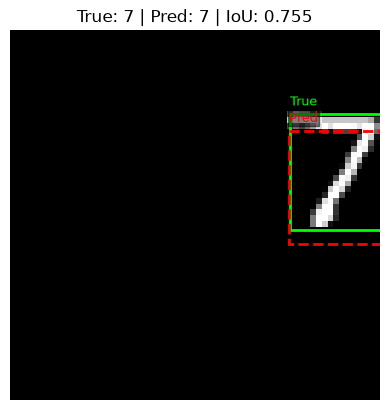

In [55]:
# 19. True Box와 Pred Box 동시에 표시

fig, ax = plt.subplots()

ax.imshow(
    sample_image.squeeze(),
    cmap="gray"
)

# 정답 Box → 초록 실선
draw_box(
    ax,
    true_box.clone(),
    64,
    "True",
    edgecolor="lime",
    linestyle="-"
)

# 예측 Box → 빨간 점선
draw_box(
    ax,
    pred_box.clone(),
    64,
    "Pred",
    edgecolor="red",
    linestyle="--"
)

ax.set_title(
    f"True: {true_label.item()} | "
    f"Pred: {pred_class} | "
    f"IoU: {sample_iou:.3f}"
)

ax.axis("off")
plt.show()


### 코드 풀이 — 화면에서 확인할 것

```text
초록 실선 → True Bounding Box
빨간 점선 → Pred Bounding Box
```

제목에는:

```text
True Class | Pred Class | IoU
```

가 표시된다.

따라서 **분류 결과와 위치 결과를 한 화면에서 동시에 확인**할 수 있다.


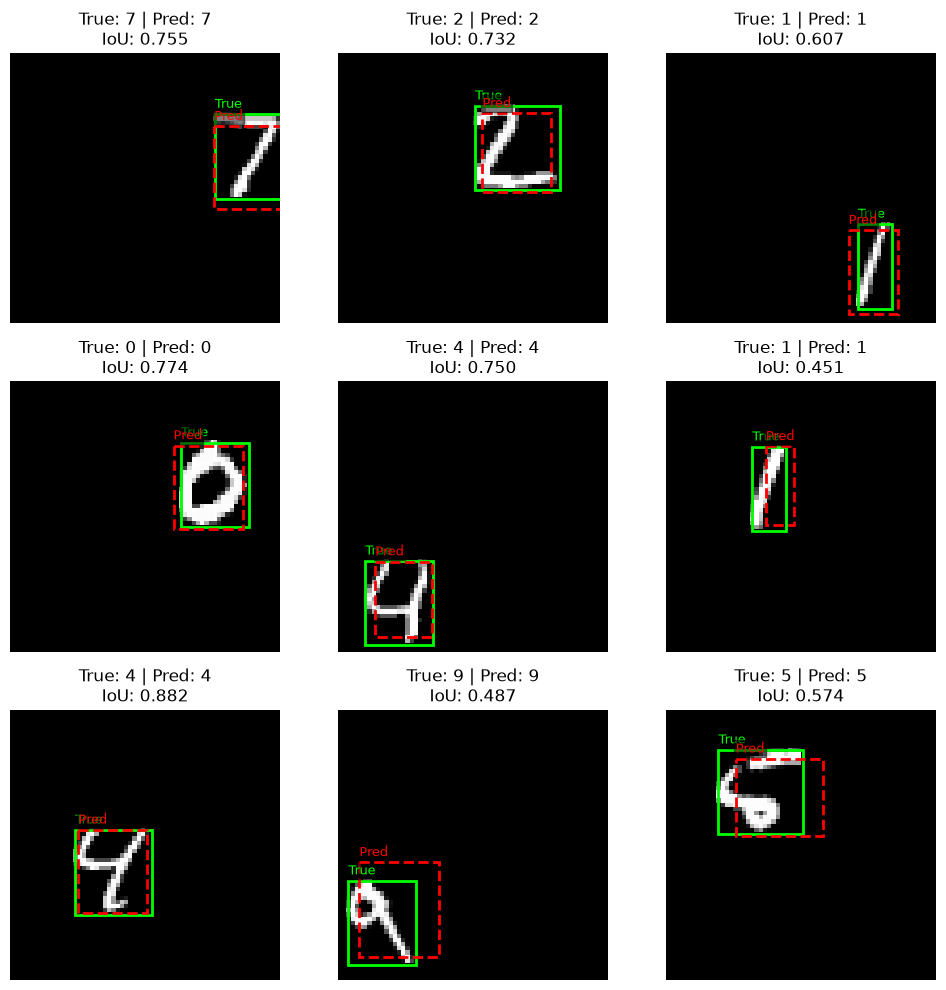

In [56]:
# 20. 여러 이미지 예측 결과 확인 — 3 × 3

model.eval()

images, labels, boxes = next(
    iter(val_loader)
)

fig, axes = plt.subplots(
    3,
    3,
    figsize=(10, 10)
)

axes = axes.flatten()

for index in range(9):

    image = images[index]
    true_label = labels[index]
    true_box = boxes[index]

    with torch.no_grad():

        class_logits, pred_boxes = model(
            image
            .unsqueeze(0)
            .to(device)
        )

    pred_class = class_logits.argmax(
        dim=1
    ).item()

    pred_box = pred_boxes[0].cpu()

    sample_iou = calculate_iou(
        pred_box.unsqueeze(0),
        true_box.unsqueeze(0)
    ).item()

    ax = axes[index]

    ax.imshow(
        image.squeeze(),
        cmap="gray"
    )

    draw_box(
        ax,
        true_box,
        64,
        "True",
        edgecolor="lime",
        linestyle="-"
    )

    draw_box(
        ax,
        pred_box,
        64,
        "Pred",
        edgecolor="red",
        linestyle="--"
    )

    ax.set_title(
        f"True: {true_label.item()} | "
        f"Pred: {pred_class}\n"
        f"IoU: {sample_iou:.3f}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()


### 코드 풀이 — 여러 결과를 보는 이유

한 장만 보면 우연히 잘 맞은 결과일 수 있다.

`3 × 3`으로 여러 결과를 동시에 보면:

```text
분류는 전체적으로 잘 되는가?
위치가 달라져도 Bounding Box가 따라가는가?
특정 위치에서 IoU가 낮아지지는 않는가?
```

를 한눈에 확인할 수 있다.


# 21. 기존 CNN과 이번 단계 비교

| 항목 | 기존 CNN | Single Object Localization |
|---|---|---|
| 입력 이미지 | O | O |
| Conv2d / ReLU / Pooling | O | O |
| Class 출력 | O | O |
| Bounding Box 출력 | X | O |
| Class Loss | O | O |
| Box Loss | X | O |
| Accuracy | O | O |
| IoU | X | O |

핵심 변화:

```text
기존 CNN
Image → CNN → Class
```

에서:

```text
Image
 ↓
CNN
 ↓
Shared Feature
 │
 ├───────────────┐
 ↓               ↓
Class            Box
```

로 확장되었다.


# 22. YOLO와 연결

현재 모델:

```text
Image
 ↓
CNN
 ↓
Class + Bounding Box 1개
```

YOLO:

```text
Image
 ↓
CNN 기반 Backbone
 ↓
Feature Maps
 ↓
Detection Head
 ↓
여러 객체의
Class + Bounding Box + Confidence
```

현재 위치를 다시 정리하면:

```text
CNN
"What?"
   ↓
Single Object Localization
"What + Where?"
   ↓
Object Detection
"여러 개의 What + Where?"
   ↓
YOLO
```

## 최종 핵심

이번 단계에서 가장 중요한 코드는 다음 네 부분이다.

```python
class_logits, pred_boxes = model(images)
class_loss = class_loss_function(class_logits, labels)
box_loss = box_loss_function(pred_boxes, boxes)
loss = class_loss + BOX_WEIGHT * box_loss
```

즉 CNN이 이제:

```text
무엇인가?
+
어디에 있는가?
```

를 동시에 학습한다.
